# JS06 (ANN) - Praktikum 5: Benchmark ANN (Recall vs Query Time)
**Mata Kuliah:** Pembelajaran Mesin  
**Nama:** Aryaputra | **NIM:** 244107020127  

---
### Deskripsi
Evaluasi trade-off antara akurasi (*Recall*) dan kecepatan pencarian (*Query Time* dalam ms/query) mengadopsi konsep ann-benchmarks.


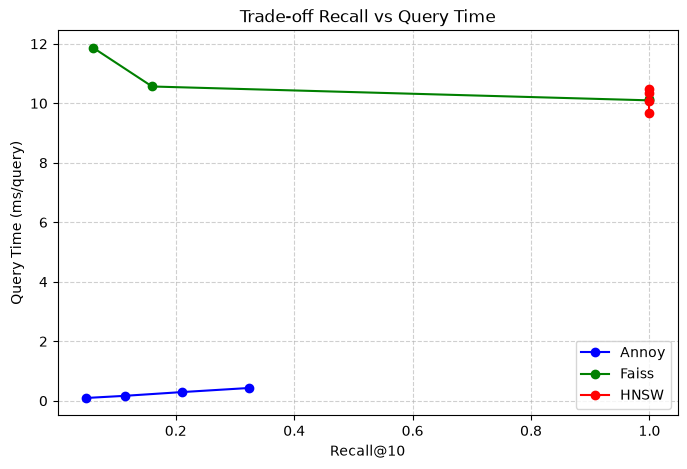

In [1]:
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt

d = 128
nb = 10000
nq = 100

np.random.seed(42)
xb = np.random.random((nb, d)).astype('float32')
xq = np.random.random((nq, d)).astype('float32')

index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
k = 10
_, gt_idx = index_flat.search(xq, k)

def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

def run_annoy(xb, xq, sk=1000):
    f = xb.shape[1]
    idx = AnnoyIndex(f, 'euclidean')
    for i, v in enumerate(xb): idx.add_item(i, v)
    idx.build(10)
    start = time.time()
    I = [idx.get_nns_by_vector(v, k, search_k=sk) for v in xq]
    elapsed = (time.time() - start) * 1000 / len(xq)
    return recall_at_k(I, gt_idx, k), elapsed

def run_faiss(xb, xq, nprobe=10):
    quantizer = faiss.IndexFlatL2(d)
    idx = faiss.IndexIVFFlat(quantizer, d, 50, faiss.METRIC_L2)
    idx.train(xb)
    idx.add(xb)
    idx.nprobe = nprobe
    start = time.time()
    _, I = idx.search(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    return recall_at_k(I, gt_idx, k), elapsed

def run_hnsw(xb, xq, ef=100):
    p = hnswlib.Index(space='l2', dim=d)
    p.init_index(max_elements=xb.shape[0], ef_construction=200, M=16)
    p.add_items(xb)
    p.set_ef(ef)
    start = time.time()
    I, _ = p.knn_query(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    return recall_at_k(I, gt_idx, k), elapsed

results = {"Annoy": [], "Faiss": [], "HNSW": []}
for sk in [100, 300, 600, 1200]: results["Annoy"].append(run_annoy(xb, xq, sk))
for npb in [1, 3, 5, 10]: results["Faiss"].append(run_faiss(xb, xq, npb))
for ef in [20, 50, 100, 150]: results["HNSW"].append(run_hnsw(xb, xq, ef))

plt.figure(figsize=(8, 5))
for label, color in zip(results.keys(), ["blue", "green", "red"]):
    rec, qtime = zip(*results[label])
    plt.plot(rec, qtime, marker="o", label=label, color=color)

plt.xlabel("Recall@10")
plt.ylabel("Query Time (ms/query)")
plt.title("Trade-off Recall vs Query Time")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()
